In [1]:
cd ..

/home/credit-score/hainh/RecSys/reputation-analysis


/home/credit-score/.local/lib/python3.10/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [7]:
!pip install optuna
!pip install seaborn

Defaulting to user installation because normal site-packages is not writeable


In [ ]:
!pip install lightgbm

Defaulting to user installation because normal site-packages is not writeable
DEPRECATION: distro-info 1.1build1 has a non-standard version number. pip 24.1 will enforce this behaviour change. A possible replacement is to upgrade to a newer version of distro-info or contact the author to suggest that they release a version with a conforming version number. Discussion can be found at https://github.com/pypa/pip/issues/12063


In [ ]:
!pip install imblearn

Defaulting to user installation because normal site-packages is not writeable
DEPRECATION: distro-info 1.1build1 has a non-standard version number. pip 24.1 will enforce this behaviour change. A possible replacement is to upgrade to a newer version of distro-info or contact the author to suggest that they release a version with a conforming version number. Discussion can be found at https://github.com/pypa/pip/issues/12063


In [ ]:
!pip install pyarrow

Defaulting to user installation because normal site-packages is not writeable
DEPRECATION: distro-info 1.1build1 has a non-standard version number. pip 24.1 will enforce this behaviour change. A possible replacement is to upgrade to a newer version of distro-info or contact the author to suggest that they release a version with a conforming version number. Discussion can be found at https://github.com/pypa/pip/issues/12063


In [ ]:
!pip install plotly


Defaulting to user installation because normal site-packages is not writeable
DEPRECATION: distro-info 1.1build1 has a non-standard version number. pip 24.1 will enforce this behaviour change. A possible replacement is to upgrade to a newer version of distro-info or contact the author to suggest that they release a version with a conforming version number. Discussion can be found at https://github.com/pypa/pip/issues/12063


In [ ]:
!pip install --upgrade nbformat


Defaulting to user installation because normal site-packages is not writeable
  Using cached nbformat-5.10.4-py3-none-any.whl.metadata (3.6 kB)
Using cached nbformat-5.10.4-py3-none-any.whl (78 kB)
DEPRECATION: distro-info 1.1build1 has a non-standard version number. pip 24.1 will enforce this behaviour change. A possible replacement is to upgrade to a newer version of distro-info or contact the author to suggest that they release a version with a conforming version number. Discussion can be found at https://github.com/pypa/pip/issues/12063
  Attempting uninstall: nbformat
    Found existing installation: nbformat 5.10.3
    Uninstalling nbformat-5.10.3:
      Successfully uninstalled nbformat-5.10.3


In [2]:
import ast
import re
import random
import optuna
import pickle
import plotly.figure_factory as ff
import numpy as np
import pandas as pd
import seaborn as sns
import lightgbm as lgb
from IPython.utils import io
import plotly.graph_objects as go
from databases.mongodb_entity import MongoDBEntity
from databases.mongodb import MongoDB
from utils.generate_training_utils import get_df_v2, get_balance_features, get_value_features, get_freq_features, search_balance_feature, get_only_value_features
import matplotlib.pyplot as plt
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import fbeta_score, precision_recall_curve, classification_report, f1_score,precision_recall_curve, auc, precision_score
from sklearn.metrics.pairwise import cosine_similarity

/home/credit-score/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
import json
with open('data/log_file/train/compound_train/1715731200/potential_wallet/potential_addresses.json.json', 'r') as f:
    data =[]
    for files in f:
        data.append(json.loads(files))


dapps_lst = []
cursor_v2 = MongoDB()._db['wallet_exchanges'].find({'_id':{'$in':data}},{'interactedWallet':1})
neighbour_addresses_lst =[]
for cur_v2 in cursor_v2:
    _id = cur_v2['_id']
    klg_cursor = MongoDBEntity()._db.wallets.find({'_id':f'{_id}'},{'_id':1,
                                                                                'tokens':1,
                                                                                'balanceInUSD':1,
                                                                                'depositInUSD':1,
                                                                                'borrowInUSD':1,
                                                                                'balanceChangeLogs':1,
                                                                                'depositChangeLogs':1,
                                                                                'borrowChangeLogs':1,
                                                                                'tokenChangeLogs':1,
                                                                                'chainId':1, 
                                                                                'tags':1})

    dapps_balance = list(klg_cursor)[0]
    if 'tags' not in dapps_balance:
        continue

    transac_df = get_df_v2(cur_v2)
    transac_df = transac_df[transac_df['timestampHistory'].apply(int)<1717470057]
    try:
        balance_df, text = get_balance_features(
        dapps_name='compound',
        lending_tags=[['compound_depositors'], ['compound_borrowers']],
        dapps_balance=dapps_balance, 
        timestamp='1717470057'
        )
    except Exception as e:
        print(e)
        print(_id)
    
    value_df = get_only_value_features(transac_df)
    freq_df = get_freq_features(transac_df)
    info_df = value_df.merge(freq_df, on='_id',how = 'inner')
    info_df = info_df.merge(balance_df, on='_id', how='inner')
    if info_df.empty == False:
        dapps_lst.append(info_df)

dapps_df = pd.concat(dapps_lst)



In [7]:
dapps_df

,_id,totalUSDTransfer,avgUSDTransfer,numInteractedToken,numInteractedWallet,addressTimeStd,tokenTimeStd,noTransaction,overallBalance,reputationScore
0,0x1_0x01d0162d7398e5ba74a692474272269228beb527,9.732980e+05,6.399612e+04,2,3,0.816497,2.500000,9,5.796288e+01,1.665897e+05
0,0x1_0x110e2c5ecf07ba0d71f58fce01f70116bbf2b85a,8.362043e+02,5.064018e+01,5,9,0.993808,1.959592,17,1.998400e+02,3.920066e+00
0,0x1_0x4b2058e3900958bf5cd38f7daa38bf7baeffb708,3.162540e+01,1.075526e+01,2,2,0.500000,0.500000,3,1.171296e+01,3.551121e+00
0,0x1_0x5fb0a30278c1b6ee4681a48f2a23bd84c2762835,6.245265e+04,8.783503e+02,9,25,1.556406,4.280302,44,1.028514e+03,1.485967e+03
0,0x1_0x6cc254cf4a6c51444c12b1b7c26e5e79b9d0d494,3.414755e+05,8.224662e+03,3,5,1.095445,1.699673,10,1.264372e+03,2.805593e+04
0,0x1_0x894a51174aeeedcf212ffb4d41905817bd04a9e4,2.628627e+04,4.432308e+01,2,8,0.707107,3.000000,12,1.556541e+02,4.310070e+03
0,0x1_0x8bca6638c6fa61f4dd9ff9ffb08899faf46f63ea,9.093766e+05,5.989565e+04,5,11,1.113404,2.280351,20,1.632026e+05,3.720266e+04
0,0x1_0xa90f726aaae3b58018e9b94d73b202b9016a44cf,3.238115e+04,7.582075e+03,1,3,0.471405,0.000000,4,3.496352e+02,8.025647e+03
0,0x1_0xbb56aad1c7d84738923fe40a538d2e0f5573a764,2.366809e+02,4.999131e+01,3,3,0.471405,0.942809,5,4.997255e+00,2.831860e+01
0,0x1_0xc906195dc6906b1dc8dea1beffee23793bc2ee0f,1.158249e+02,3.221540e+01,2,4,0.000000,1.000000,4,2.967399e+00,1.633333e+01


In [ ]:
fig = go.Figure(data=[go.Histogram(x=dapps_df.reputationScore.tolist())])
fig.update_layout(
    title="Sample Histogram",
    xaxis_title="Value",
    yaxis_title="Frequency"
)

# Show plot
fig.show()




In [27]:
df_search

,_id,totalUSDTransfer,avgUSDTransfer,numInteractedToken,numInteractedWallet,addressTimeStd,tokenTimeStd,noTransaction,overallBalance
0,0x1_0x008a74d96d799b0fcfae8462bfff8c37c7ccc611,172985.246191,3281.385083,4,8,0.695971,2.165064,13,760.359177
1,0x1_0x017d534264e4580bde76e84bbdc2b2c3bd477605,1330.753194,665.376597,2,2,0.000000,0.000000,2,81.536539
2,0x1_0x03a01b74c6aea11d38c41e4c557f01a9041aa2f0,85634.037613,403.017684,9,14,16.476947,24.198255,144,7795.137042
3,0x1_0x0523c8321be7aff81dd68d52650db63fc095782e,1351.453987,1351.453987,1,1,0.000000,0.000000,1,2386.347877
4,0x1_0x081de256389d3cb6df846ccb6396549f4b4b5e29,134.369390,5.338289,3,3,0.471405,0.942809,5,22.623862
...,...,...,...,...,...,...,...,...,...
995,0x38_0x7cf00ba6a7c50029a0617f0702d9ec8f1eb17e7e,46769.704859,205.286753,5,5,15.291828,15.291828,53,1839.698545
996,0x38_0x7cf1b718a6dec482e60c7014ab86df23c42f91dc,30.965580,2.292486,1,4,1.785357,0.000000,15,65.866668
997,0x38_0x7d16ab8c819ff4656dcab01d8c30263f6eac341c,0.676667,0.676667,1,1,0.000000,0.000000,1,1.066640
998,0x38_0x7d6959e523e4bd19537d831fe54be2c638ae7fea,1.084534,1.084534,1,1,0.000000,0.000000,1,0.618854


In [ ]:
def get_label(row):
    if 1000<row<1000000:
        return 1
    else: 
        return 0

df_search = pd.read_parquet("data/search/search_1716681600.parquet")
#df = pd.read_parquet("data/trava/train/train_1716681600.parquet")
df = pd.read_parquet('data/modeling/compound/train/train_1715731200.parquet')
df['label'] = df['reputationScore'].apply(get_label)

X = df.drop(["_id","label", "reputationScore"], axis=1)
y = df["label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.05, random_state=42)



In [15]:
df.value_counts('label')

label
0    51229
1     2246
Name: count, dtype: int64

In [16]:
X_test

,addressTimeStd,avgUSDTransfer,noTransaction,numInteractedToken,numInteractedWallet,overallBalance,tokenTimeStd,totalUSDTransfer
0,13.435608,13.914356,73,42,15,2851.588516,1.589542,4541.407690
0,3.419064,951.855922,31,13,10,2150.366061,1.777572,84216.028125
0,0.000000,42.825470,3,3,3,136.972563,0.000000,126.915231
0,0.000000,36.230121,5,5,1,105.826831,0.000000,716.106398
0,3.091206,48.150837,11,11,3,231.830033,0.000000,584.575923
...,...,...,...,...,...,...,...,...
0,2.748737,363.127845,32,11,12,8688.604328,4.521756,25690.732255
0,0.000000,7.616618,2,1,2,2.880515,0.000000,15.233236
0,2.078271,1235.180578,92,3,74,308898.191117,41.955002,284572.045146
0,1.049781,237.131002,22,6,14,2014.759162,2.924988,5042.292951


In [25]:
def LGBMTraining(X_train, y_train, num_leaves,feature_fraction,max_depth,sampling_strategy, k):
    smote = SMOTE(sampling_strategy=sampling_strategy, k_neighbors=k)
    params = {
    'objective': 'multiclass',
    'metric': 'multi_logloss',
    'num_classes': 2,  # Number of classes in your classification problem
    'num_leaves': num_leaves,  #31
    'learning_rate': 0.05,
    'feature_fraction': feature_fraction,  #0.9
    'max_depth': max_depth
#   'device':'gpu'
    }
    with io.capture_output() as captured:
        X_trainn, X_val, y_trainn, y_val = train_test_split(X_train, y_train, test_size=0.05, random_state=42)
        X_train_res, y_train_res = smote.fit_resample(X_trainn, y_trainn.ravel())
        train_data = lgb.Dataset(X_train_res, label=pd.DataFrame(y_train_res), params={'verbose': -1})
        test_data = lgb.Dataset(pd.DataFrame(X_val), label=pd.DataFrame(y_val), params={'verbose': -1}, reference=train_data)
        num_round = 100  # Number of boosting rounds
        evals={}
        bst = lgb.train(params,train_data, num_round, valid_sets=[train_data, test_data],callbacks = [lgb.record_evaluation(evals)])
        y_pred = bst.predict(X_test, num_iteration=bst.best_iteration)
        y_pred_class = np.argmax(y_pred, axis=1)
        F1_score = precision_score(y_test, y_pred_class, average='weighted',pos_label = 1)
    return bst, F1_score,evals

def get_LGBMscore(trial):
    num_leaves = trial.suggest_int('num_leaves', 160, 300, 10) 
    feature_fraction = trial.suggest_float('feature_fraction', 0.4, 0.8, step=0.1)
    max_depth = trial.suggest_int('max_depth', 35, 55, 1)
    sampling_strategy = trial.suggest_float('sampling_strategy', 0.15, 0.5,step=0.1)
    k = trial.suggest_categorical('k', [2, 3, 5, 7,9,11])
    models, F1_scores, evals = LGBMTraining(X_train, y_train, num_leaves,feature_fraction,max_depth, sampling_strategy, k)
    
    
    with open("data/results/compound_models_{}.pickle".format(trial.number), "wb") as fout:
        pickle.dump(models, fout)
        
    with open("data/results/compound_evals_{}.pickle".format(trial.number), "wb") as fout:
        pickle.dump(evals, fout)
    return np.mean(F1_scores)

def optimization(n):
    # define custom values to search on:
    study = optuna.create_study(study_name="Optimization over given values",direction='maximize')
    study.optimize(get_LGBMscore, n_trials = n)
    best_params = study.best_params
    best_metric = study.best_value
    return best_params, best_metric, study

In [26]:
best_params, best_metric, study = optimization(5)


[I 2024-06-04 03:26:40,074] A new study created in memory with name: Optimization over given values
/home/credit-score/.local/lib/python3.10/site-packages/optuna/distributions.py:685: UserWarning:

The distribution is specified by [0.15, 0.5] and step=0.1, but the range is not divisible by `step`. It will be replaced by [0.15, 0.45].

[W 2024-06-04 03:27:18,297] Trial 0 failed with parameters: {'num_leaves': 300, 'feature_fraction': 0.5, 'max_depth': 49, 'sampling_strategy': 0.25, 'k': 9} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/home/credit-score/.local/lib/python3.10/site-packages/optuna/study/_optimize.py", line 200, in _run_trial
    value_or_values = func(trial)
  File "/tmp/ipykernel_4076479/188387920.py", line 32, in get_LGBMscore
    models, F1_scores, evals = LGBMTraining(X_train, y_train, num_leaves,feature_fraction,max_depth, sampling_strategy, k)
  File "/tmp/ipykernel_4076479/188387920.py", line 20, in LGBMTraining
   

KeyboardInterrupt: 

<Axes: title={'center': 'Metric during training'}, xlabel='Iterations', ylabel='multi_logloss'>

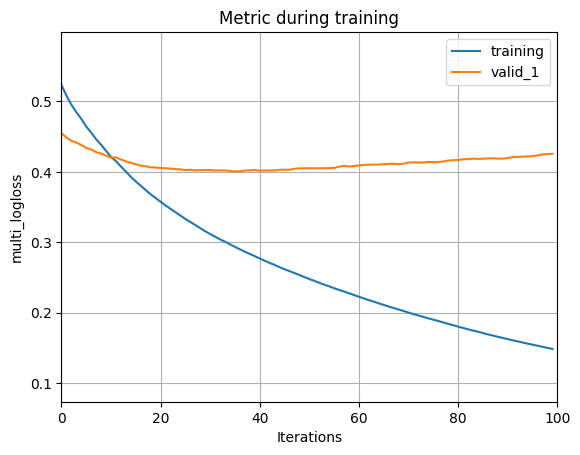

In [ ]:
evals = pickle.load(open(f"/kaggle/working/evals_{study.best_trial.number}.pickle", 'rb'))


In [ ]:
model = pickle.load(open(f"data/aave/modeling/models_0.pickle", 'rb'))
y_pred = model.predict(X_test, num_iteration=model.best_iteration)
y_pred_class = np.argmax(y_pred, axis=1)

F1_score = fbeta_score(y_test, y_pred_class, pos_label = True,beta=1)
precision, recall, threshold = precision_recall_curve(y_test, y_pred_class)
pr_auc = auc(recall, precision)
print(
F1_score
)

print(
pr_auc
)

0.35036496350364965
0.5207721576206696


In [ ]:
print(classification_report(y_test, y_pred_class))


              precision    recall  f1-score   support

           0       0.90      0.39      0.54       140
           1       0.23      0.81      0.35        31

    accuracy                           0.46       171
   macro avg       0.56      0.60      0.45       171
weighted avg       0.78      0.46      0.51       171



In [ ]:
from collections import Counter


In [ ]:
observation = df_search.drop('_id', axis=1)

In [ ]:
y_pred = model.predict(observation, num_iteration=model.best_iteration)
y_pred_class = np.argmax(y_pred, axis=1)


In [ ]:
element_counts = Counter(y_pred_class)
element_counts

Counter({0: 1279283, 1: 39717})